# Modelo de Ising — Análisis preliminar

En esta notebook vamos a estudiar **termalización y autocorrelaciones** antes de elegir los parámetros de nuestras simulaciones definitivas de la guía 4.

La idea es aprovechar el mismo algoritmo de Metropolis que ya validamos, pero guardar ahora series temporales completas de energía y magnetización. Compararemos configuraciones iniciales ordenadas y aleatorias, y estimaremos los tiempos de autocorrelación relevantes para las incertidumbres estadísticas.

**Importante:** estos son estudios exploratorios. No vamos a decidir un tiempo de termalización mirando una sola trayectoria, ni suponer que guardar una configuración cada cierto número de MCS la convierte en independiente.

## 1. Generación de datos

Desde la raíz del repositorio, compilamos:

```bash
g++ -std=c++17 -O2 -Wall -Wextra main.cpp -o ising_sim
```

El modo preliminar acepta una semilla, el tamaño de red, la temperatura, la condición inicial, la cantidad total de barridos y el intervalo de guardado. Por ejemplo:

```bash
./ising_sim 12345 --prelim 16 2.26918531 random 20000 1
./ising_sim 67890 --prelim 16 2.26918531 ordered 20000 1
```

Cada combinación de parámetros tiene un nombre de CSV diferente en `preliminar_data/`. **Si repetimos exactamente los mismos parámetros y semilla, el archivo correspondiente se sobrescribe**; para conservar realizaciones diferentes usamos semillas diferentes. Cada CSV contiene `MCS`, `Energy_per_spin` y `Mag_per_spin`, incluyendo la configuración inicial (`MCS=0`). Un MCS representa **N intentos de inversión con elección aleatoria del sitio**, no necesariamente una visita a cada sitio.

Comenzaremos con corridas piloto; luego aumentaremos los tiempos en los casos que lo requieran (especialmente cerca de $T_c$ y para $L$ grandes). Por ahora usamos $J=1$, $B=0$.

Para comparar las condiciones iniciales, usamos **semillas distintas**: las trayectorias no deben coincidir punto por punto; sus observables deben ser estadísticamente compatibles tras la relajación.

## 2. Librerías y lectura de datos

Primero localizamos las series temporales disponibles. La notebook está pensada para ejecutarse desde la **raíz del repositorio**, donde también se encuentra `main.cpp`.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("preliminar_data")
GRAPH_DIR = Path("preliminar_graphs")
SAVE_FIGURES = False  # Cambiar a True si queremos guardar las figuras.

TC_EXACT = 2.0 / np.log(1.0 + np.sqrt(2.0))
print(f"Temperatura crítica exacta (J=k_B=1): Tc = {TC_EXACT:.8f}")

Temperatura crítica exacta (J=k_B=1): Tc = 2.26918531


In [2]:
pattern = re.compile(
    r"prelim_L=(?P<L>\d+)_T=(?P<T>\d+(?:\.\d+)?)_init=(?P<initial>random|ordered)_seed=(?P<seed>\d+)\.csv"
)

records = []
for path in sorted(DATA_DIR.glob("prelim_*.csv")):
    match = pattern.fullmatch(path.name)
    if match:
        info = match.groupdict()
        records.append({
            "L": int(info["L"]), "T": float(info["T"]),
            "initial": info["initial"], "seed": int(info["seed"]),
            "path": path,
        })

files = pd.DataFrame(records, columns=["L", "T", "initial", "seed", "path"])
if files.empty:
    print("Todavía no hay series preliminares. Ejecutá los comandos de la sección 1.")
else:
    display(files.drop(columns="path"))

,L,T,initial,seed
0,16,2.269185,ordered,67890
1,16,2.269185,random,12345
2,32,2.269185,ordered,67890
3,32,2.269185,random,12345


### Revisión rápida de los datos

Antes de analizar nada, comprobamos algunas restricciones físicas. A campo nulo, con $J=1$, para una red cuadrada con primeros vecinos se cumple $-2\leq e\leq 2$ y $|m|\leq 1$ en **cada configuración**. Esto sirve para detectar errores de energía como el que encontramos en las simulaciones anteriores.

In [3]:
REQUIRED = {"MCS", "Energy_per_spin", "Mag_per_spin"}

def load_series(path):
    df = pd.read_csv(path)
    if not REQUIRED.issubset(df.columns):
        raise ValueError(f"Faltan columnas en {path}")
    df = df.sort_values("MCS").reset_index(drop=True)
    if df.empty or df["MCS"].iloc[0] != 0:
        raise ValueError(f"La serie debe empezar en MCS=0: {path}")
    if not np.all(np.diff(df["MCS"].to_numpy()) > 0):
        raise ValueError(f"MCS duplicados o no crecientes en {path}")
    vals = df[["Energy_per_spin", "Mag_per_spin"]].to_numpy()
    if not np.isfinite(vals).all():
        raise ValueError(f"Datos no finitos en {path}")
    if (np.abs(df["Mag_per_spin"]) > 1.0 + 1e-10).any():
        raise ValueError(f"Magnetización fuera del rango físico en {path}")
    if (np.abs(df["Energy_per_spin"]) > 2.0 + 1e-9).any():
        raise ValueError(f"Energía fuera del rango físico (J=1, B=0) en {path}")
    return df

for path in files.get("path", []):
    load_series(path)
print(f"Series revisadas: {len(files)}")

Series revisadas: 4


## 3. Termalización: condición inicial ordenada vs. aleatoria

En equilibrio, los promedios termodinámicos no deberían depender de la condición inicial. Vamos a comparar $e(t)$ y $|m(t)|$ comenzando tanto de una red ordenada como de una red aleatoria.

Usamos $|m|$ porque a campo nulo el signo de $m$ puede cambiar por la simetría $\mathbb{Z}_2$. En un sistema finito, una transición de $m>0$ a $m<0$ no implica por sí misma pérdida del equilibrio.

**Cuidado:** que dos trayectorias se aproximen visualmente no prueba que el sistema haya termalizado; también vamos a observar qué ocurre al aumentar el tiempo simulado y repetir algunas semillas.

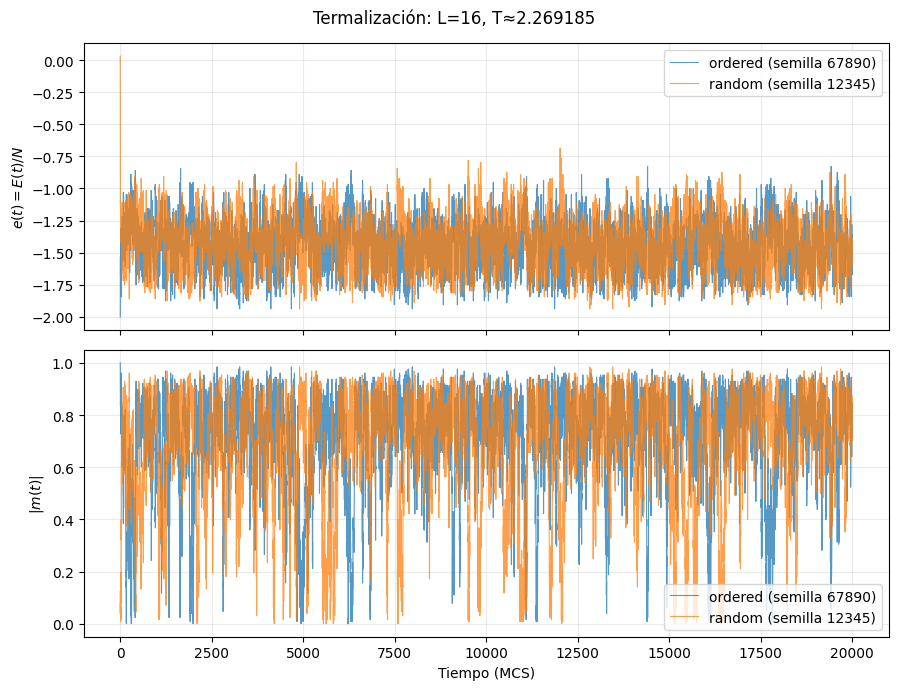

In [4]:
# Combinación de L y T a estudiar. Cambiaremos estas variables al pasar a otros tamaños.
L_VIEW = 16
T_VIEW = TC_EXACT
T_TOL = 5e-4

# Semillas de las DOS corridas que queremos comparar (actualizarlas para futuras corridas).
SEED_BY_INITIAL = {"ordered": 67890, "random": 12345}

subset = files[(files["L"] == L_VIEW) & ((files["T"] - T_VIEW).abs() < T_TOL)]
selected_runs = {}
for initial, seed in SEED_BY_INITIAL.items():
    choices = subset[(subset["initial"] == initial) & (subset["seed"] == seed)]
    if choices.empty:
        print(f"Falta la serie para L={L_VIEW}, T≈{T_VIEW:.6f}, {initial}, semilla={seed}")
    else:
        selected_runs[initial] = choices.iloc[0]

if selected_runs:
    fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    for initial, selected in selected_runs.items():
        df = load_series(selected["path"])
        label = f"{initial} (semilla {selected['seed']})"
        axes[0].plot(df["MCS"], df["Energy_per_spin"], lw=0.8, alpha=0.75, label=label)
        axes[1].plot(df["MCS"], df["Mag_per_spin"].abs(), lw=0.8, alpha=0.75, label=label)
    axes[0].set_ylabel(r"$e(t)=E(t)/N$")
    axes[1].set_ylabel(r"$|m(t)|$")
    axes[1].set_xlabel("Tiempo (MCS)")
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend()
    fig.suptitle(f"Termalización: L={L_VIEW}, T≈{T_VIEW:.6f}")
    fig.tight_layout()
    if SAVE_FIGURES:
        GRAPH_DIR.mkdir(exist_ok=True)
        fig.savefig(GRAPH_DIR / f"termalizacion_L={L_VIEW}_T={T_VIEW:.6f}.png", dpi=180)
    plt.show()


### Zoom del transitorio inicial

El gráfico completo comprime los primeros barridos. Repetimos la visualización para los **primeros 500 MCS** (sin volver a simular) y comparamos cómo se acercan ambas condiciones iniciales a una misma región de fluctuaciones. Que ambas trayectorias se crucen o tengan valores parecidos no constituye, por sí solo, una prueba de equilibrio.

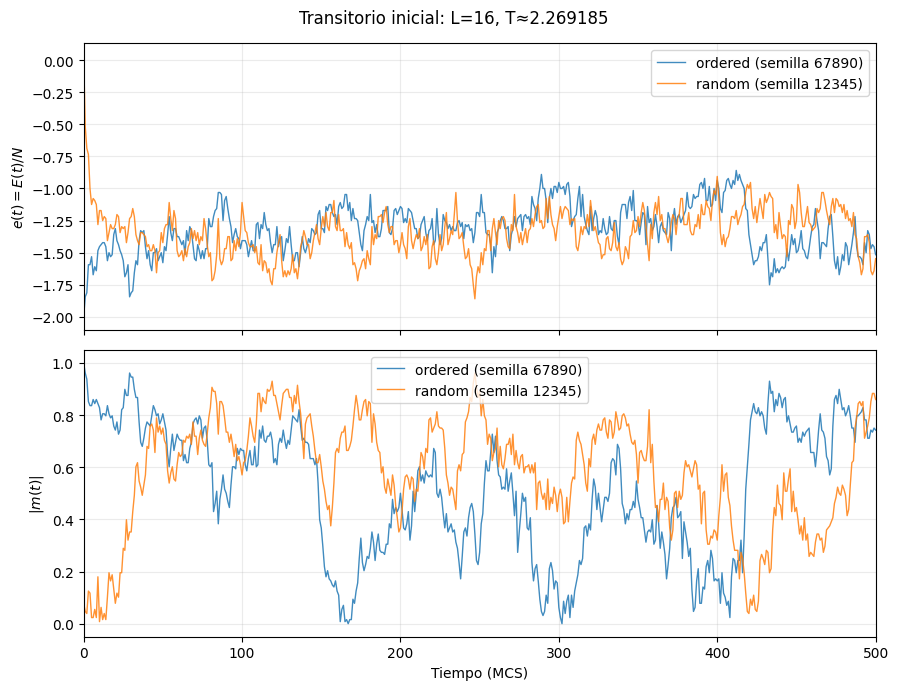

In [5]:
ZOOM_MCS = 500

if selected_runs:
    fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    for initial, selected in selected_runs.items():
        df = load_series(selected["path"])
        df = df[df["MCS"] <= ZOOM_MCS]
        label = f"{initial} (semilla {selected['seed']})"
        axes[0].plot(df["MCS"], df["Energy_per_spin"], lw=1, alpha=0.85, label=label)
        axes[1].plot(df["MCS"], df["Mag_per_spin"].abs(), lw=1, alpha=0.85, label=label)
    axes[0].set_ylabel(r"$e(t)=E(t)/N$")
    axes[1].set_ylabel(r"$|m(t)|$")
    axes[1].set_xlabel("Tiempo (MCS)")
    for ax in axes:
        ax.set_xlim(0, ZOOM_MCS)
        ax.grid(alpha=0.25)
        ax.legend()
    fig.suptitle(f"Transitorio inicial: L={L_VIEW}, T≈{T_VIEW:.6f}")
    fig.tight_layout()
    if SAVE_FIGURES:
        GRAPH_DIR.mkdir(exist_ok=True)
        fig.savefig(GRAPH_DIR / f"termalizacion_zoom_L={L_VIEW}_T={T_VIEW:.6f}.png", dpi=180)
    plt.show()


## 4. Autocorrelaciones

Una vez descartado un tramo inicial que consideremos suficientemente largo, analizaremos la autocorrelación normalizada

$$
\rho_A(t)=\frac{\langle A(s)A(s+t)\rangle-\langle A\rangle^2}{\langle A^2\rangle-\langle A\rangle^2}.
$$

Nos interesa el **tiempo de autocorrelación integrado**

$$
\tau_{\mathrm{int},A}=\frac{1}{2}+\sum_{t=1}^\infty\rho_A(t),
$$

que determina el error del promedio. Por eso no alcanza con localizar el retardo en el que $\rho=1/e$: ese sería un tiempo característico exponencial, diferente de $\tau_{\mathrm{int}}$ en general.

Usaremos la energía y $|m|$. A baja temperatura, la magnetización con signo puede tener inversiones globales muy raras que dificultan mucho la estimación de su tiempo de autocorrelación. Calcularemos la autocorrelación con FFT para evitar el costo de evaluar cada retardo de forma independiente.

La suma infinita se trunca con una **ventana autoconsistente** aproximada $W\approx 5\tau_{\mathrm{int}}$. Si el resultado se acerca al máximo retardo disponible, hay que realizar una serie más larga; no tomar la cifra como definitiva.

In [6]:
def autocorrelation_fft(x, max_lag=None):
    # Autocorrelación normalizada, calculada por FFT.
    x = np.asarray(x, dtype=float)
    n = len(x)
    if n < 10:
        raise ValueError("Serie demasiado corta")
    x = x - x.mean()
    var = np.mean(x**2)
    if var <= 1e-25:
        raise ValueError("El observable casi no fluctúa; no puede estimarse su autocorrelación")
    nfft = 1 << (2 * n - 1).bit_length()
    fx = np.fft.rfft(x, nfft)
    corr = np.fft.irfft(fx * fx.conj(), nfft)[:n].real
    corr = corr / np.arange(n, 0, -1)  # Normalización por pares disponibles en cada retardo.
    rho = corr / corr[0]
    if max_lag is not None:
        rho = rho[:max_lag + 1]
    return rho


def integrated_time(rho, c=5.0):
    # Estimación preliminar mediante ventana autoconsistente.
    max_lag = len(rho) - 1
    window = 1
    tau = 0.5
    for _ in range(100):
        new_window = min(max(1, int(np.ceil(c * tau))), max_lag)
        new_tau = max(0.5, 0.5 + np.sum(rho[1:new_window + 1]))
        if new_window == window and abs(new_tau - tau) < 1e-9:
            break
        window, tau = new_window, new_tau
    return tau, window, (window < max_lag)

### Una primera estimación de $\tau_{\mathrm{int}}$

Elegimos una serie y descartamos un tiempo inicial. **`DISCARD_MCS` es una elección exploratoria**, no un tiempo de termalización ya validado: lo ajustaremos en función de los gráficos anteriores.

Para comparar tiempos entre series guardadas con distintos intervalos, convertimos $\tau_{\mathrm{int}}$ a MCS multiplicando por el intervalo de guardado. La estimación de muestras efectivas es

$$
N_{\mathrm{eff}}\approx \frac{N_{\mathrm{muestras}}}{2\tau_{\mathrm{int}}^{\mathrm{(muestras)}}}.
$$

Solo es una aproximación razonable si la cadena está en equilibrio y la estimación de $\tau_{\mathrm{int}}$ es estable.

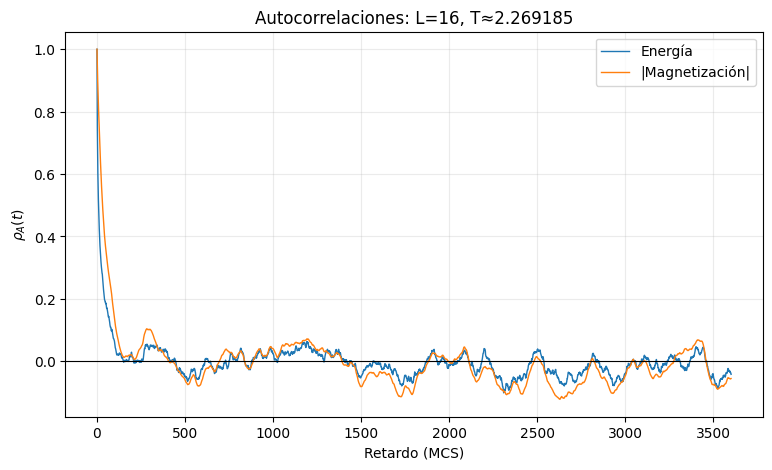

,Observable,tau_int (MCS),Ventana (MCS),N_eff aprox.,Ventana no saturada
0,Energía,24.57,123,366.34,True
1,|Magnetización|,46.88,235,192.00,True


In [7]:
DISCARD_MCS = 2000   # Exploratorio: NO usar como conclusión de termalización.
INITIAL_VIEW = "random"

if INITIAL_VIEW not in selected_runs:
    print("No hay datos para estudiar autocorrelaciones con estos parámetros.")
else:
    selected = selected_runs[INITIAL_VIEW]
    df = load_series(selected["path"])
    df = df[df["MCS"] >= DISCARD_MCS].copy()
    dts = np.diff(df["MCS"].to_numpy())
    if len(dts) < 20:
        print("Muy pocas muestras después de descartar el tramo inicial.")
    else:
        dt = int(pd.Series(dts).mode().iloc[0])
        # Excluir el último punto si se guardó excepcionalmente fuera de la grilla regular.
        df = df[df["MCS"] % dt == 0].copy()
        max_lag = min(len(df) // 5, 10000)
        fig, ax = plt.subplots(figsize=(9, 5))
        summary = []
        for name, values in {
            "Energía": df["Energy_per_spin"],
            "|Magnetización|": df["Mag_per_spin"].abs(),
        }.items():
            rho = autocorrelation_fft(values, max_lag=max_lag)
            tau, window, ok_window = integrated_time(rho)
            tau_mcs = tau * dt
            neff = len(df) / (2 * tau)
            summary.append({"Observable": name, "tau_int (MCS)": tau_mcs,
                            "Ventana (MCS)": window * dt,
                            "N_eff aprox.": neff,
                            "Ventana no saturada": ok_window})
            ax.plot(np.arange(len(rho)) * dt, rho, label=name, lw=1)
        ax.axhline(0, color="black", lw=0.8)
        ax.set(xlabel="Retardo (MCS)", ylabel=r"$\rho_A(t)$",
               title=f"Autocorrelaciones: L={L_VIEW}, T≈{T_VIEW:.6f}")
        ax.legend()
        ax.grid(alpha=0.25)
        plt.show()
        display(pd.DataFrame(summary).round(2))
        if not all(x["Ventana no saturada"] for x in summary):
            print("Atención: la ventana alcanzó el retardo máximo; repetir con una serie más larga.")

## 5. Comprobación de estabilidad: tiempo descartado y condición inicial

Para cada trayectoria estimamos el promedio, el error del promedio y el tiempo de autocorrelación integrado **después de descartar** 500, 1000, 2000 y 4000 MCS. Comparamos energía y $|m|$ entre las dos condiciones iniciales, siempre usando semillas distintas.

La incertidumbre preliminar del promedio se aproxima por

$$
\mathrm{SE}(\overline A)\simeq\sqrt{\frac{2\tau_{\mathrm{int},A}}{n}\,s_A^2},
$$

donde $\tau_{\mathrm{int},A}$ se expresa en **intervalos de medición**, $n$ es la cantidad de valores guardados y $s_A^2$ la varianza muestral. Esta fórmula supone equilibrio y una estimación razonable de $\tau_{\mathrm{int}}$. Los intervalos obtenidos con diferentes descartes se superponen, por lo que sus promedios **no son independientes**. Buscamos estabilidad y compatibilidad estadística, no coincidencia exacta ni un tiempo mínimo de termalización.

In [8]:
DISCARDS_MCS = [500, 1000, 2000, 4000]
MAX_LAG_MCS = 2000  # Límite exploratorio de la autocorrelación, expresado en MCS.

# Evita incluir un último punto guardado fuera del intervalo regular de medición.
def regular_series(path):
    df = load_series(path)
    gaps = np.diff(df["MCS"].to_numpy())
    if len(gaps) == 0:
        raise ValueError(f"Serie sin suficientes datos: {path}")
    dt = int(pd.Series(gaps).mode().iloc[0])
    if dt <= 0:
        raise ValueError(f"Intervalo de medición inválido: {path}")
    df = df[df["MCS"] % dt == 0].copy()
    if not np.all(np.diff(df["MCS"].to_numpy()) == dt):
        raise ValueError(f"La serie no tiene intervalos de medición regulares: {path}")
    return df, dt

results = []
for initial, selected in selected_runs.items():
    df_full, dt = regular_series(selected["path"])
    for discard in DISCARDS_MCS:
        df = df_full[df_full["MCS"] >= discard]
        if len(df) < 30:
            print(f"Muy pocos puntos: {initial}, descarte={discard} MCS")
            continue
        for observable, values in {
            "e": df["Energy_per_spin"].to_numpy(),
            "|m|": df["Mag_per_spin"].abs().to_numpy(),
        }.items():
            try:
                max_lag = min(len(values) // 5, MAX_LAG_MCS // dt)
                rho = autocorrelation_fft(values, max_lag=max_lag)
                tau, window, ok = integrated_time(rho)
                if not ok:
                    print(f"Atención: ventana saturada para {initial}, {observable}, descarte={discard}")
                error = np.sqrt(2 * tau * np.var(values, ddof=1) / len(values))
                results.append({
                    "Inicial": initial,
                    "Semilla": int(selected["seed"]),
                    "Descartados (MCS)": discard,
                    "Observable": observable,
                    "Promedio": np.mean(values),
                    "Error aprox.": error,
                    "tau_int (MCS)": tau * dt,
                    "N_eff aprox.": len(values) / (2 * tau),
                    "Ventana OK": ok,
                })
            except ValueError as exc:
                print(f"No se pudo estimar {initial}, {observable}: {exc}")

stability = pd.DataFrame(results)
if stability.empty:
    print("No hay suficientes datos para la tabla de estabilidad.")
else:
    display(stability.round({"Promedio": 5, "Error aprox.": 5,
                             "tau_int (MCS)": 2, "N_eff aprox.": 1}))


,Inicial,Semilla,Descartados (MCS),Observable,Promedio,Error aprox.,tau_int (MCS),N_eff aprox.,Ventana OK
0,ordered,67890,500,e,-1.45491,0.00719,16.74,582.3,True
1,ordered,67890,500,|m|,0.71782,0.01231,43.66,223.3,True
2,ordered,67890,1000,e,-1.45550,0.00740,17.18,553.1,True
3,ordered,67890,1000,|m|,0.71734,0.01260,43.95,216.2,True
4,ordered,67890,2000,e,-1.45817,0.00745,16.76,536.9,True
5,ordered,67890,2000,|m|,0.72116,0.01308,47.02,191.4,True
6,ordered,67890,4000,e,-1.45594,0.00833,18.40,434.9,True
7,ordered,67890,4000,|m|,0.71800,0.01456,49.52,161.6,True
8,random,12345,500,e,-1.43310,0.00915,24.85,392.3,True
9,random,12345,500,|m|,0.68253,0.01477,46.66,209.0,True


### Comprobación adicional: dos mitades de la serie

Sin generar nuevos datos, dividimos cada trayectoria **posterior al descarte** en dos mitades y estimamos nuevamente los tiempos de autocorrelación. Este control es orientativo: al dividir una serie también reducimos la precisión, por lo que es esperable cierta dispersión entre estimaciones. Tomamos 2000 MCS como descarte **provisional**, no como conclusión.

In [9]:
HALVES_DISCARD_MCS = 2000
halves_results = []

for initial, selected in selected_runs.items():
    df_full, dt = regular_series(selected["path"])
    df = df_full[df_full["MCS"] >= HALVES_DISCARD_MCS]
    midpoint = len(df) // 2
    for part, segment in (("Primera mitad", df.iloc[:midpoint]),
                          ("Segunda mitad", df.iloc[midpoint:])):
        if len(segment) < 30:
            continue
        for observable, values in {
            "e": segment["Energy_per_spin"].to_numpy(),
            "|m|": segment["Mag_per_spin"].abs().to_numpy(),
        }.items():
            try:
                rho = autocorrelation_fft(values,
                    max_lag=min(len(values) // 5, MAX_LAG_MCS // dt))
                tau, window, ok = integrated_time(rho)
                halves_results.append({
                    "Inicial": initial, "Mitad": part,
                    "Observable": observable,
                    "Promedio": np.mean(values),
                    "tau_int (MCS)": tau * dt,
                    "Ventana OK": ok,
                })
            except ValueError as exc:
                print(f"No se pudo calcular {initial}, {part}, {observable}: {exc}")

if halves_results:
    display(pd.DataFrame(halves_results).round(4))
else:
    print("No hay suficientes datos para comparar mitades.")


,Inicial,Mitad,Observable,Promedio,tau_int (MCS),Ventana OK
0,ordered,Primera mitad,e,-1.4543,17.1856,True
1,ordered,Primera mitad,|m|,0.7156,60.6833,True
2,ordered,Segunda mitad,e,-1.4621,16.3008,True
3,ordered,Segunda mitad,|m|,0.7267,35.2166,True
4,random,Primera mitad,e,-1.4225,20.5467,True
5,random,Primera mitad,|m|,0.6665,35.9744,True
6,random,Segunda mitad,e,-1.4429,28.4447,True
7,random,Segunda mitad,|m|,0.6970,59.9755,True


## 6. ¿Qué nos falta decidir?

A partir de los resultados de esta notebook queremos responder:

1. **Termalización.** ¿Desde qué tiempo las trayectorias ordenadas y aleatorias muestran un comportamiento estacionario compatible? ¿Se mantiene al repetir semillas?
2. **Autocorrelación.** ¿Cuáles son los tiempos integrados de energía y $|m|$ para cada $L$ y $T$? ¿Son estables al variar el tiempo descartado y el retardo máximo?
3. **Producción.** ¿Cuántos MCS necesitaremos para obtener un número razonable de muestras efectivas, sobre todo cerca de $T_c$? ¿Qué intervalo de guardado conviene usar?

Vamos a explorar progresivamente los cinco tamaños cerca de $T_c$, usando ambas condiciones iniciales. Después decidiremos qué temperaturas alejadas de $T_c$ conviene verificar y qué series necesitan prolongarse. **No vamos a fijar los parámetros finales hasta observar estas mediciones.**

Esta notebook está separada de `analysis.ipynb`, que quedará reservada para los resultados definitivos y los apartados (a)–(g) de la guía.

## 7. Comparación entre todos los tamaños a $T_c$

Queremos estudiar los cinco tamaños exigidos por la guía, $L=16,32,64,128,200$, con **configuraciones ordenadas y aleatorias independientes**. Esta sección detecta automáticamente qué CSV están disponibles y no falla si todavía faltan corridas. Las secciones anteriores conservan el análisis detallado de $L=16$.

Empezamos cerca de la temperatura crítica exacta del sistema infinito, donde el *critical slowing down* suele ser más exigente. **No asumimos que la misma duración sea suficiente para todos los tamaños.** Primero haremos corridas piloto en $L=32$ y $L=64$. Con sus autocorrelaciones estimaremos el esfuerzo requerido para $L=128$ y $L=200$.

Para generar las próximas series (desde la carpeta raíz del repositorio), podemos empezar por:

```bash
./ising_sim 12345 --prelim 32 2.26918531 random 20000 1
./ising_sim 67890 --prelim 32 2.26918531 ordered 20000 1
```

Después de analizar $L=32$, elegiremos la duración de las corridas de $L=64$. **Los 20000 MCS anteriores son un piloto, no una prescripción estadística para las corridas finales.**


In [10]:
# Tamaños solicitados por la consigna.
L_VALUES = [16, 32, 64, 128, 200]
T_COMPARISON = TC_EXACT
T_TOL_ALL = 5e-4
SEEDS_ALL = {"random": 12345, "ordered": 67890}

# Ventanas visuales orientativas para observar el transitorio (NO tiempos de termalización).
ZOOM_BY_L = {16: 500, 32: 1000, 64: 2000, 128: 4000, 200: 8000}

runs_by_L = {}
run_inventory = []
for L in L_VALUES:
    candidates = files[
        (files["L"] == L) & ((files["T"] - T_COMPARISON).abs() <= T_TOL_ALL)
    ]
    runs = {}
    for initial, seed in SEEDS_ALL.items():
        choices = candidates[
            (candidates["initial"] == initial) & (candidates["seed"] == seed)
        ]
        if not choices.empty:
            runs[initial] = choices.iloc[0]
        run_inventory.append({
            "L": L, "Inicial": initial, "Semilla": seed,
            "Disponible": not choices.empty,
        })
    runs_by_L[L] = runs

inventory = pd.DataFrame(run_inventory)
display(inventory)
missing = inventory[~inventory["Disponible"]]
if not missing.empty:
    print("\nSeries todavía pendientes (se incorporarán automáticamente al ejecutar nuevamente):")
    display(missing[["L", "Inicial", "Semilla"]].reset_index(drop=True))


,L,Inicial,Semilla,Disponible
0,16,random,12345,True
1,16,ordered,67890,True
2,32,random,12345,True
3,32,ordered,67890,True
4,64,random,12345,False
5,64,ordered,67890,False
6,128,random,12345,False
7,128,ordered,67890,False
8,200,random,12345,False
9,200,ordered,67890,False



Series todavía pendientes (se incorporarán automáticamente al ejecutar nuevamente):


,L,Inicial,Semilla
0,64,random,12345
1,64,ordered,67890
2,128,random,12345
3,128,ordered,67890
4,200,random,12345
5,200,ordered,67890


### 7.1. Transitorios de energía y magnetización

Comparamos ambas condiciones iniciales para **cada tamaño con datos disponibles**. Usamos ventanas de visualización distintas para que el transitorio de los sistemas grandes no quede comprimido. El cruce de dos trayectorias no prueba termalización; lo contrastaremos con promedios y autocorrelaciones.


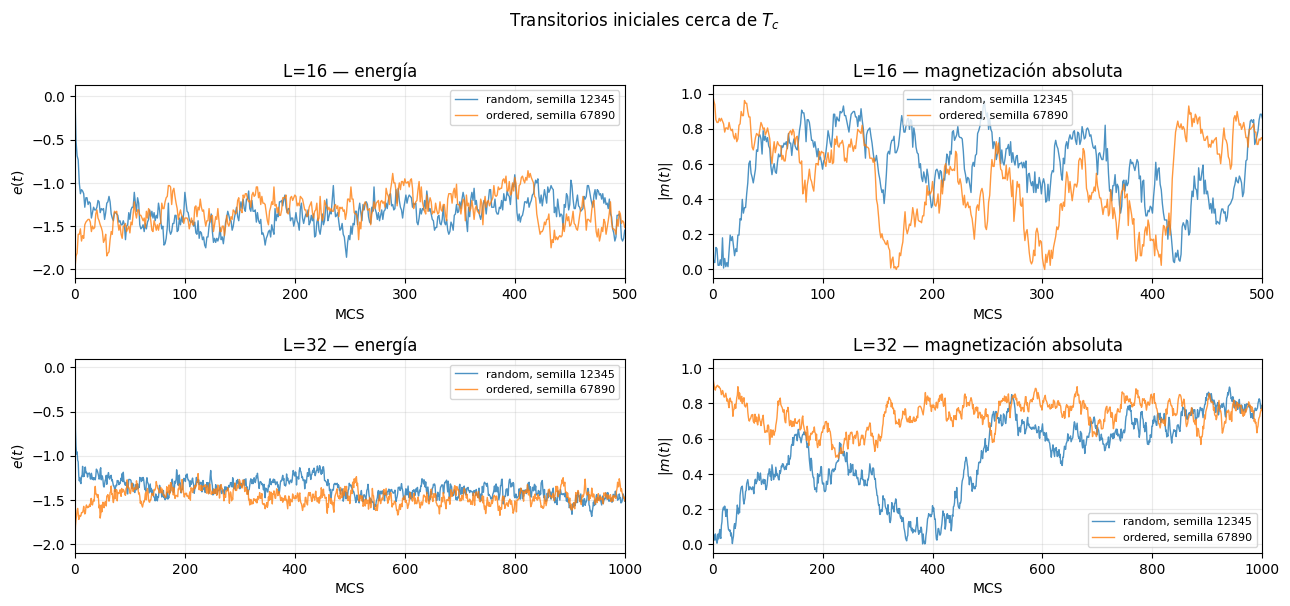

In [11]:
sizes_with_data = [L for L in L_VALUES if runs_by_L.get(L)]

if not sizes_with_data:
    print("No hay series cerca de Tc para mostrar.")
else:
    fig, axes = plt.subplots(len(sizes_with_data), 2, figsize=(13, 3.0 * len(sizes_with_data)), squeeze=False)
    for row, L in enumerate(sizes_with_data):
        zoom = ZOOM_BY_L[L]
        for initial, selected in runs_by_L[L].items():
            df = load_series(selected["path"])
            part = df[df["MCS"] <= zoom]
            label = f"{initial}, semilla {selected['seed']}"
            axes[row, 0].plot(part["MCS"], part["Energy_per_spin"], lw=1.0, alpha=0.8, label=label)
            axes[row, 1].plot(part["MCS"], part["Mag_per_spin"].abs(), lw=1.0, alpha=0.8, label=label)
        axes[row, 0].set(title=f"L={L} — energía", xlabel="MCS", ylabel=r"$e(t)$", xlim=(0, zoom))
        axes[row, 1].set(title=f"L={L} — magnetización absoluta", xlabel="MCS", ylabel=r"$|m(t)|$", xlim=(0, zoom))
        for ax in axes[row]:
            ax.grid(alpha=0.25)
            ax.legend(fontsize=8)
    fig.suptitle(r"Transitorios iniciales cerca de $T_c$", y=1.002)
    fig.tight_layout()
    if SAVE_FIGURES:
        GRAPH_DIR.mkdir(exist_ok=True)
        fig.savefig(GRAPH_DIR / "transitorios_todos_los_tamanos.png", dpi=180, bbox_inches="tight")
    plt.show()


### 7.2. Autocorrelaciones y tamaño del sistema

La siguiente tabla utiliza **un descarte provisional del 10 % de cada serie**, solamente para explorar la dependencia con $L$. No lo interpretamos como una justificación de termalización: el descarte final se elegirá revisando los transitorios y comparaciones de promedios.

Para cada serie se estiman $\tau_{\mathrm{int},E}$ y $\tau_{\mathrm{int},|m|}$ con la misma ventana autoconsistente de la sección 4. La columna `N_eff aprox.` estima cuántas observaciones independientes equivalentes contiene el tramo analizado. `Evaluación` advierte si la ventana quedó truncada o hay pocas muestras efectivas; en esos casos los resultados **no deben utilizarse como estimaciones definitivas**.

**Atención:** una estimación de $\tau_{\mathrm{int}}$ puede estar sesgada a la baja si la trayectoria es corta respecto de los modos lentos. Aumentar $L$ sin aumentar suficientemente la duración no garantiza una estimación fiable.


In [12]:
DISCARD_FRACTION_PILOT = 0.10  # Solo orientativo; NO un criterio definitivo.
MAX_ACF_LAG_MCS = 100_000        # Límite computacional amplio; no fija el tiempo de correlación.
MIN_NEFF_PILOT = 50              # Umbral orientativo para advertir poca estadística.

all_size_rows = []
for L in L_VALUES:
    for initial, selected in runs_by_L[L].items():
        df_full, dt = regular_series(selected["path"])
        total_mcs = int(df_full["MCS"].iloc[-1])
        discard_mcs = int(np.floor(total_mcs * DISCARD_FRACTION_PILOT / dt) * dt)
        df = df_full[df_full["MCS"] >= discard_mcs]
        if len(df) < 50:
            print(f"Serie demasiado corta para L={L}, {initial}")
            continue
        for obs, x in {
            "e": df["Energy_per_spin"].to_numpy(),
            "|m|": df["Mag_per_spin"].abs().to_numpy(),
        }.items():
            try:
                max_lag = min(len(x) // 4, MAX_ACF_LAG_MCS // dt)
                if max_lag < 5:
                    raise ValueError("Retardo máximo insuficiente")
                rho = autocorrelation_fft(x, max_lag=max_lag)
                tau_steps, window, window_ok = integrated_time(rho)
                neff = len(x) / (2 * tau_steps)
                warnings = []
                if not window_ok:
                    warnings.append("ventana truncada")
                if neff < MIN_NEFF_PILOT:
                    warnings.append("N_eff bajo")
                assessment = ", ".join(warnings) if warnings else "exploratorio"
                all_size_rows.append({
                    "L": L, "Inicial": initial, "Observable": obs,
                    "MCS totales": total_mcs, "Descarte piloto": discard_mcs,
                    "Promedio": x.mean(),
                    "Error aprox.": np.sqrt(2 * tau_steps * np.var(x, ddof=1) / len(x)),
                    "tau_int (MCS)": tau_steps * dt,
                    "N_eff aprox.": neff,
                    "Evaluación": assessment,
                })
            except ValueError as exc:
                print(f"No se pudo estimar L={L}, {initial}, {obs}: {exc}")

size_summary = pd.DataFrame(all_size_rows)
if size_summary.empty:
    print("Faltan series suficientemente largas para el resumen por tamaños.")
else:
    display(size_summary.round({"Promedio": 5, "Error aprox.": 5,
                                "tau_int (MCS)": 2, "N_eff aprox.": 1}))


,L,Inicial,Observable,MCS totales,Descarte piloto,Promedio,Error aprox.,tau_int (MCS),N_eff aprox.,Evaluación
0,16,random,e,20000,2000,-1.43269,0.00949,24.57,366.3,exploratorio
1,16,random,|m|,20000,2000,0.68176,0.01546,46.88,192.0,exploratorio
2,16,ordered,e,20000,2000,-1.45817,0.00745,16.76,536.9,exploratorio
3,16,ordered,|m|,20000,2000,0.72116,0.01308,47.02,191.4,exploratorio
4,32,random,e,20000,2000,-1.43448,0.00861,70.13,128.3,exploratorio
5,32,random,|m|,20000,2000,0.64598,0.03494,310.61,29.0,N_eff bajo
6,32,ordered,e,20000,2000,-1.43813,0.00751,58.37,154.2,exploratorio
7,32,ordered,|m|,20000,2000,0.66710,0.02269,165.27,54.5,exploratorio


### 7.3. Evolución de los tiempos integrados con $L$

La figura permite visualizar el *critical slowing down* sin ajustar todavía un exponente dinámico $z$ (la guía no lo solicita). Las curvas son **orientativas** hasta confirmar que cada serie está equilibrada y tiene suficiente longitud en comparación con sus tiempos de autocorrelación.


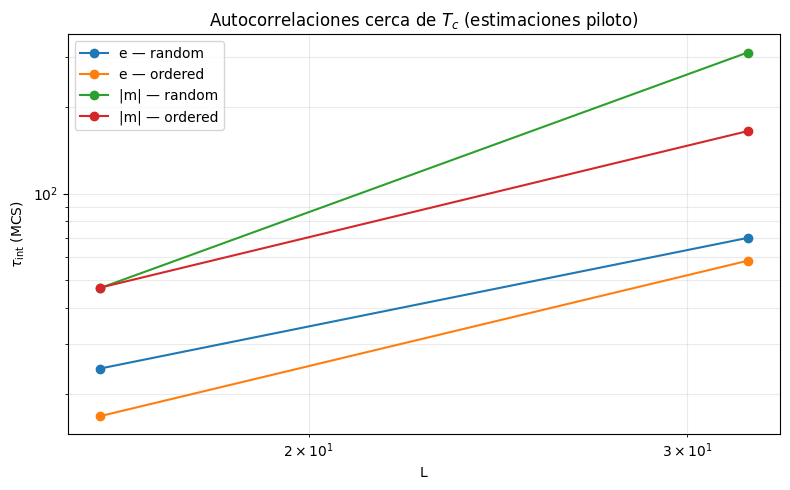

In [13]:
if size_summary.empty:
    print("Todavía no hay tiempos de autocorrelación para graficar.")
else:
    fig, ax = plt.subplots(figsize=(8, 5))
    for observable in ["e", "|m|"]:
        for initial in ["random", "ordered"]:
            d = size_summary[(size_summary["Observable"] == observable) &
                             (size_summary["Inicial"] == initial)].sort_values("L")
            if d.empty:
                continue
            ax.plot(d["L"], d["tau_int (MCS)"], "o-", label=f"{observable} — {initial}")
    ax.set(xlabel="L", ylabel=r"$\tau_{\mathrm{int}}$ (MCS)",
           title=r"Autocorrelaciones cerca de $T_c$ (estimaciones piloto)")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.grid(alpha=0.25, which="both")
    ax.legend()
    fig.tight_layout()
    if SAVE_FIGURES:
        GRAPH_DIR.mkdir(exist_ok=True)
        fig.savefig(GRAPH_DIR / "tau_integrado_vs_L_piloto.png", dpi=180)
    plt.show()


### Próximas decisiones

Con los datos de $L=32$ discutiremos si es suficiente continuar al siguiente tamaño o necesitamos prolongar alguna trayectoria. Para $L=64$, $128$ y $200$ seleccionaremos duraciones nuevas de forma progresiva, sin extrapolar como válidos los tiempos o intervalos de muestreo del código antiguo. Más adelante también examinaremos temperaturas por encima y por debajo de $T_c$; la región crítica es nuestro primer caso exigente, no la única condición a validar.
